# **Project Name**    - Bank Marketing: Exploratory Data Analysis with Apache Spark


##### **Project Type**    - EDA
##### **Contribution**    - Individual
##### **Team Member 1 -** Taha Saifee


# **Project Summary -**

This notebook is Part 2 of my distributed machine learning project on bank data: exploratory data analysis with Apache Spark. The data is the bank marketing dataset (bank.csv) from the phone campaigns of a Portuguese bank. Every row is one client who was called during a campaign that sold term deposits. There are 4,521 clients and 17 columns: personal details (age, job, marital status, education), financial details (credit in default, account balance, housing loan, personal loan), details of the last contact in this campaign (contact type, day, month, call duration, number of contacts), details of earlier campaigns (pdays, previous, poutcome) and the target y, which says if the client subscribed to a term deposit.

I did all the processing in PySpark and not in pandas. The data is loaded into a Spark DataFrame, and every filter, group by, aggregation, user defined function and SQL query runs in Spark. Only small results that are already aggregated are converted to pandas for the charts. On this file Spark is not faster than pandas, because 4,521 rows fit easily in memory, but the same code would run unchanged on a cluster with millions of rows, because Spark splits the data into partitions and processes them in parallel.

The data is clean in the usual sense: there are no null values and no duplicate rows. Missing information is written as "unknown" instead. 3,705 clients (82%) have an unknown previous outcome because they were never contacted before, 1,324 have an unknown contact type, 187 an unknown education and 38 an unknown job. I kept "unknown" as its own category, because "never contacted before" is real information.

The target is imbalanced: only 521 clients (11.5%) subscribed. The strongest patterns are about the campaign more than about the client. Clients with a successful outcome in an earlier campaign subscribed 64.3% of the time, against 9.1% for clients contacted for the first time. Calls that ended in a subscription lasted 552.7 seconds on average against 226.3 seconds for the others, although the duration is only known after the call. The bank made 30.9% of all its calls in May (1,398 calls), and May had the lowest success rate of all months at 6.65%, while October, December and March converted more than 40% of a much smaller number of calls. Clients with a known phone (cellular or telephone) subscribed about three times as often (around 14.5%) as clients whose contact type is unknown (4.6%).

Among the client attributes, age has a U shape: clients under 30 subscribed 15.4% of the time, clients between 30 and 60 only 10.2%, and clients over 60 37.8%. Retired clients have the highest average balance (2,319). Tertiary education converts better than primary (14.3% against 9.4%). Having a housing loan or a personal loan goes with a lower rate: clients with neither loan subscribed 16.9% of the time and clients with both only 6.2%. The balance is very skewed, with a median of 444 and a maximum of 71,188, and the correlation between age and balance is only 0.084.

For the business this means the bank could get more subscriptions from the same number of calls: call clients with a past success first, spread the calls over the year instead of putting a third of them in May, pay more attention to clients over 60 and students, and fix the missing contact details. These findings also guide the features and the handling of the class imbalance in the Spark ML model of Part 3.

# **GitHub Link -**

https://github.com/Tahascommit/bank-distributed-ml

(this notebook is `part2_spark_eda/Spark_EDA_Bank_Marketing.ipynb` in the repo)

# **Problem Statement**


**Problem Statement**

A Portuguese bank sells term deposits through phone campaigns. Most calls end without a sale (only 11.5% of the clients in this data subscribed), so a lot of call centre time goes to clients who were never going to say yes. The bank has data about its clients and its earlier campaigns, but it does not know which types of clients, months, contact channels and campaign histories go together with a subscription. This is also the kind of data that grows quickly in a real bank, so the analysis should be done with a tool that scales. In this notebook I use Apache Spark to explore the bank marketing data and find what separates the clients who subscribed from the ones who did not.

#### **Define Your Business Objective?**

Find the client groups and campaign conditions with the highest chance of a subscription, so the bank can call the right clients at the right time and get more term deposits from fewer calls. At the same time, do the analysis with Spark, so that it can run on the full volume of the bank's data and not only on this sample.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 20 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





# ***Let's Begin !***

## ***1. Know Your Data***

#### Part 2 Q1: Data Loading and Basic Inspection

This question is answered by the cells of this section and the next one: loading bank.csv into a Spark DataFrame (Dataset Loading), the first rows (Dataset First View), the schema (Dataset Information) and the summary of the numerical columns (Dataset Describe).

### Import Libraries

In [1]:
# Import Libraries
# Setup first, so the notebook runs both on my laptop and on Google Colab
import os, sys, glob, time, subprocess, importlib.util, urllib.request, warnings
warnings.filterwarnings("ignore")

# Spark runs on Java. On my Mac, Java 17 comes from Homebrew. On Colab I install it if needed
LOCAL_JAVA = "/opt/homebrew/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home"


def java_major():
    """Major version of the java on the PATH, or None if there is no java."""
    try:
        out = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
    except FileNotFoundError:
        return None
    version = out.split('"')[1] if '"' in out else ""
    parts = version.split(".")
    major = parts[1] if parts[0] == "1" and len(parts) > 1 else parts[0]   # java 8 reports 1.8.x
    return int(major) if major.isdigit() else None


if os.path.isdir(LOCAL_JAVA):
    os.environ["JAVA_HOME"] = LOCAL_JAVA
elif java_major() not in (8, 11, 17):   # Spark 3.5 runs on Java 8, 11 or 17
    subprocess.run("apt-get update -qq > /dev/null 2>&1 && apt-get install -y -qq openjdk-17-jdk-headless > /dev/null 2>&1",
                   shell=True, check=True)
    os.environ["JAVA_HOME"] = glob.glob("/usr/lib/jvm/java-17-openjdk-*")[0]

# PySpark is already installed on my laptop, on Colab it gets installed here
if importlib.util.find_spec("pyspark") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark==3.5.9"], check=True)

# Spark starts separate Python workers for UDFs, they must use the same Python as this notebook
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# keep Spark's startup log quiet, otherwise its warnings end up in the cell output.
# (the two loggers below are the ones that warn on a laptop: hostname and native hadoop libraries)
import tempfile
LOG4J = os.path.join(tempfile.gettempdir(), "spark-log4j2-quiet.properties")
with open(LOG4J, "w") as f:
    f.write("rootLogger.level = warn\n"
            "rootLogger.appenderRef.console.ref = console\n"
            "appender.console.type = Console\n"
            "appender.console.name = console\n"
            "appender.console.target = SYSTEM_ERR\n"
            "appender.console.layout.type = PatternLayout\n"
            "appender.console.layout.pattern = %d{HH:mm:ss} %p %c{1}: %m%n\n"
            "logger.utils.name = org.apache.spark.util.Utils\n"
            "logger.utils.level = error\n"
            "logger.native.name = org.apache.hadoop.util.NativeCodeLoader\n"
            "logger.native.level = error\n")
os.environ["PYSPARK_SUBMIT_ARGS"] = f"--driver-java-options -Dlog4j2.configurationFile=file:{LOG4J} pyspark-shell"

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StringType
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# chart colours: one blue for single series, fixed colours for "no" and "yes"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8c959f"
YES_NO = {"no": BLUE, "yes": ORANGE}
sns.set_theme(style="whitegrid")
plt.rcParams.update({"axes.titlesize": 13, "axes.titleweight": "bold"})
print("libraries loaded")

libraries loaded


### Dataset Loading

In [2]:
# Load Dataset
# Part 2 Q1: load bank.csv into a Spark DataFrame
LOCAL_DATA = "../data/bank.csv"
DATA_URL = "https://raw.githubusercontent.com/Tahascommit/bank-distributed-ml/main/data/bank.csv"
if os.path.exists(LOCAL_DATA):
    DATA_PATH = LOCAL_DATA
else:
    # on Colab: Spark can't read from a URL, so the file is downloaded first
    DATA_PATH = "bank.csv"
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

spark = (SparkSession.builder
         .master("local[*]")                       # every core of this machine works as an executor
         .appName("bank-marketing-eda")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

df = spark.read.csv(DATA_PATH, header=True, inferSchema=True)
print("Spark version:", spark.version)
print("cores available to Spark:", spark.sparkContext.defaultParallelism)
print("data loaded from:", DATA_PATH)

Spark version: 3.5.9
cores available to Spark: 12
data loaded from: ../data/bank.csv


### Dataset First View

In [3]:
# Dataset First Look
# Part 2 Q1: the first few rows
df.show(5)

+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|age|        job|marital|education|default|balance|housing|loan| contact|day|month|duration|campaign|pdays|previous|poutcome|  y|
+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
| 30| unemployed|married|  primary|     no|   1787|     no|  no|cellular| 19|  oct|      79|       1|   -1|       0| unknown| no|
| 33|   services|married|secondary|     no|   4789|    yes| yes|cellular| 11|  may|     220|       1|  339|       4| failure| no|
| 35| management| single| tertiary|     no|   1350|    yes|  no|cellular| 16|  apr|     185|       1|  330|       1| failure| no|
| 30| management|married| tertiary|     no|   1476|    yes| yes| unknown|  3|  jun|     199|       4|   -1|       0| unknown| no|
| 59|blue-collar|married|secondary|     no|      0|    yes|  no| unknown|  5|  may|     22

### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
print(f"rows: {df.count()}, columns: {len(df.columns)}")

rows: 4521, columns: 17


### Dataset Information

In [5]:
# Dataset Info
# Part 2 Q1: the schema that Spark inferred from the csv
df.printSchema()
print("partitions:", df.rdd.getNumPartitions())

root
 |-- age: integer (nullable = true)
 |-- job: string (nullable = true)
 |-- marital: string (nullable = true)
 |-- education: string (nullable = true)
 |-- default: string (nullable = true)
 |-- balance: integer (nullable = true)
 |-- housing: string (nullable = true)
 |-- loan: string (nullable = true)
 |-- contact: string (nullable = true)
 |-- day: integer (nullable = true)
 |-- month: string (nullable = true)
 |-- duration: integer (nullable = true)
 |-- campaign: integer (nullable = true)
 |-- pdays: integer (nullable = true)
 |-- previous: integer (nullable = true)
 |-- poutcome: string (nullable = true)
 |-- y: string (nullable = true)

partitions: 1


#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
duplicates = df.count() - df.dropDuplicates().count()
print("duplicate rows:", duplicates)

duplicate rows: 0


#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count
# real nulls, counted for every column in one pass over the data
df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).show()

# this dataset writes missing categories as the text "unknown", so I count those too
cat_cols = [c for c, t in df.dtypes if t == "string"]
unknowns = df.select([F.sum((F.col(c) == "unknown").cast("int")).alias(c) for c in cat_cols])
unknowns.show()
print("clients never contacted before (pdays = -1):", df.filter(F.col("pdays") == -1).count())

+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+
|age|job|marital|education|default|balance|housing|loan|contact|day|month|duration|campaign|pdays|previous|poutcome|  y|
+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+
|  0|  0|      0|        0|      0|      0|      0|   0|      0|  0|    0|       0|       0|    0|       0|       0|  0|
+---+---+-------+---------+-------+-------+-------+----+-------+---+-----+--------+--------+-----+--------+--------+---+



+---+-------+---------+-------+-------+----+-------+-----+--------+---+
|job|marital|education|default|housing|loan|contact|month|poutcome|  y|
+---+-------+---------+-------+-------+----+-------+-----+--------+---+
| 38|      0|      187|      0|      0|   0|   1324|    0|    3705|  0|
+---+-------+---------+-------+-------+----+-------+-----+--------+---+

clients never contacted before (pdays = -1): 3705


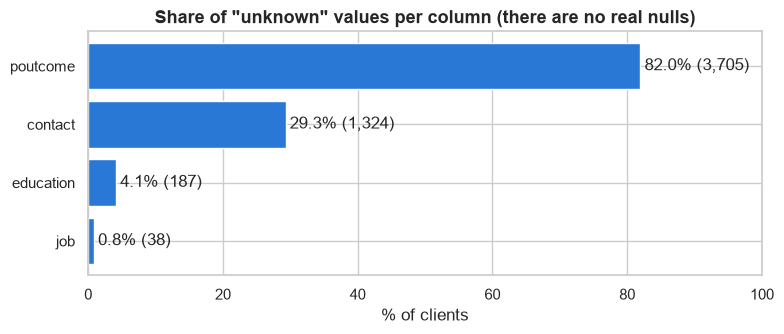

In [8]:
# Visualizing the missing values
# share of "unknown" per column (one row of numbers, so converting to pandas is cheap)
unknown_pct = (unknowns.toPandas().T.rename(columns={0: "unknown"})
               .assign(pct=lambda t: 100 * t["unknown"] / df.count())
               .sort_values("pct"))
unknown_pct = unknown_pct[unknown_pct["unknown"] > 0]

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(unknown_pct.index, unknown_pct["pct"], color=BLUE)
ax.bar_label(bars, labels=[f"{p:.1f}% ({n:,})" for p, n in zip(unknown_pct["pct"], unknown_pct["unknown"])], padding=3)
ax.set(title='Share of "unknown" values per column (there are no real nulls)', xlabel="% of clients", xlim=(0, 100))
plt.tight_layout()
plt.show()

### What did you know about your dataset?

- The dataset has 4,521 rows and 17 columns: 7 integer columns (age, balance, day, duration, campaign, pdays, previous) and 10 text columns.
- Spark read the file into 1 partition, because the file is only about 375 KB. On my laptop Spark has 12 cores available.
- There are no null values and no duplicate rows.
- 4 columns use the word "unknown" for missing values: poutcome (3,705 clients, 82%), contact (1,324, 29%), education (187, 4.1%) and job (38, 0.8%). pdays is -1 for the same 3,705 clients, which means they were never contacted in an earlier campaign.
- The target y is imbalanced: 4,000 "no" and 521 "yes" (11.5%).

## ***2. Understanding Your Variables***

In [9]:
# Dataset Columns
print(df.columns)

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


In [10]:
# Dataset Describe
# Part 2 Q1: summary of the numerical columns (count, mean, stddev, min, quartiles, max)
num_cols = [c for c, t in df.dtypes if t == "int"]
df.select(num_cols).summary().show()

+-------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+
|summary|               age|           balance|               day|          duration|          campaign|             pdays|          previous|
+-------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+
|  count|              4521|              4521|              4521|              4521|              4521|              4521|              4521|
|   mean| 41.17009511170095|1422.6578190665782|15.915284229152842|263.96129174961294| 2.793629727936297|39.766644547666445|0.5425790754257908|
| stddev|10.576210958711263|3009.6381424673395| 8.247667327229934|259.85663262468216|3.1098066601885823|100.12112444301656|1.6935623506071211|
|    min|                19|             -3313|                 1|                 4|                 1|                -1|                 0|

### Variables Description

| Column | Type | Meaning |
|---|---|---|
| age | int | age of the client (19 to 87) |
| job | string | type of job (12 values, including "unknown") |
| marital | string | married, single or divorced |
| education | string | primary, secondary, tertiary or unknown |
| default | string | does the client have credit in default (yes/no) |
| balance | int | average yearly balance of the account, can be negative (-3,313 to 71,188) |
| housing | string | does the client have a housing loan (yes/no) |
| loan | string | does the client have a personal loan (yes/no) |
| contact | string | how the client was contacted: cellular, telephone or unknown |
| day | int | day of the month of the last contact |
| month | string | month of the last contact (jan to dec) |
| duration | int | length of the last call in seconds |
| campaign | int | number of contacts with this client during this campaign |
| pdays | int | days since the client was last contacted in an earlier campaign, -1 if never |
| previous | int | number of contacts before this campaign |
| poutcome | string | outcome of the earlier campaign: success, failure, other or unknown |
| y | string | target: did the client subscribe to a term deposit (yes/no) |

Columns I added in the data wrangling: month_num and quarter (from month), age_group (from the UDF) and job_marital (job and marital joined).

### Check Unique Values for each variable.

In [11]:
# Check Unique Values for each variable.
# countDistinct for every column in one Spark job, shown as a small table
df.agg(*[F.countDistinct(c).alias(c) for c in df.columns]).toPandas().T.rename(columns={0: "unique values"})

,unique values
age,67
job,12
marital,3
education,4
default,2
balance,2353
housing,2
loan,2
contact,3
day,31


## 3. ***Data Wrangling***

#### Data Wrangling Code

Every Part 2 question is answered below with Spark. Each one has its own heading.

In [12]:
# Write your code to make your dataset analysis ready.
# 1 if the client subscribed to a term deposit, 0 if not. The average of this is the subscription rate
yes = F.when(F.col("y") == "yes", 1).otherwise(0)

#### Part 2 Q2: Data Filtering and Column Operations

Clients with a balance greater than 1,000, then the month number and the quarter of the year.

In [13]:
# filter: clients with a balance above the threshold
BALANCE_THRESHOLD = 1000
high_balance = df.filter(F.col("balance") > BALANCE_THRESHOLD)
print(f"clients with a balance above {BALANCE_THRESHOLD}: {high_balance.count()} of {df.count()}")
high_balance.select("age", "job", "marital", "balance", "y").show(5)

clients with a balance above 1000: 1481 of 4521
+---+----------+-------+-------+---+
|age|       job|marital|balance|  y|
+---+----------+-------+-------+---+
| 30|unemployed|married|   1787| no|
| 33|  services|married|   4789| no|
| 35|management| single|   1350| no|
| 30|management|married|   1476| no|
| 39|  services|married|   9374| no|
+---+----------+-------+-------+---+
only showing top 5 rows



In [14]:
# month name -> month number -> quarter, with a map column (no python code runs per row)
MONTHS = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_map = F.create_map(*[F.lit(x) for i, m in enumerate(MONTHS) for x in (m, i + 1)])

df = (df.withColumn("month_num", month_map[F.col("month")])
        .withColumn("quarter", F.concat(F.lit("Q"), F.ceil(F.col("month_num") / 3).cast("int"))))
df.select("month", "month_num", "quarter").distinct().orderBy("month_num").show(12)

+-----+---------+-------+
|month|month_num|quarter|
+-----+---------+-------+
|  jan|        1|     Q1|
|  feb|        2|     Q1|
|  mar|        3|     Q1|
|  apr|        4|     Q2|
|  may|        5|     Q2|
|  jun|        6|     Q2|
|  jul|        7|     Q3|
|  aug|        8|     Q3|
|  sep|        9|     Q3|
|  oct|       10|     Q4|
|  nov|       11|     Q4|
|  dec|       12|     Q4|
+-----+---------+-------+



#### Part 2 Q3: GroupBy and Aggregation

Average balance and median age per job, and the number of subscribers per marital status.

In [15]:
# per job: number of clients, average balance and median age (percentile_approx is the distributed median)
job_stats = (df.groupBy("job")
               .agg(F.count("*").alias("clients"),
                    F.round(F.avg("balance"), 2).alias("avg_balance"),
                    F.percentile_approx("age", 0.5).alias("median_age"))
               .orderBy(F.desc("avg_balance")))
job_stats.show()

+-------------+-------+-----------+----------+
|          job|clients|avg_balance|median_age|
+-------------+-------+-----------+----------+
|      retired|    230|    2319.19|        59|
|    housemaid|    112|     2083.8|        49|
|   management|    969|    1766.93|        38|
| entrepreneur|    168|    1645.13|        41|
|      student|     84|    1543.82|        26|
|      unknown|     38|    1501.71|        49|
|self-employed|    183|    1392.41|        40|
|   technician|    768|     1331.0|        38|
|       admin.|    478|    1226.74|        38|
|     services|    417|    1103.96|        37|
|   unemployed|    128|    1089.42|        41|
|  blue-collar|    946|    1085.16|        39|
+-------------+-------+-----------+----------+



In [16]:
# per marital status: how many clients subscribed to a term deposit
marital_subs = (df.groupBy("marital")
                  .agg(F.count("*").alias("clients"),
                       F.sum(yes).alias("subscribed"),
                       F.round(100 * F.avg(yes), 2).alias("subscription_rate_pct"))
                  .orderBy(F.desc("subscribed")))
marital_subs.show()

+--------+-------+----------+---------------------+
| marital|clients|subscribed|subscription_rate_pct|
+--------+-------+----------+---------------------+
| married|   2797|       277|                  9.9|
|  single|   1196|       167|                13.96|
|divorced|    528|        77|                14.58|
+--------+-------+----------+---------------------+



#### Part 2 Q4: UDF to Categorize Age Groups

A Python UDF that puts every client in '<30', '30-60' or '>60', added as the column age_group.

In [17]:
@F.udf(returnType=StringType())
def age_group(age):
    """Age group of a client: '<30', '30-60' or '>60'."""
    if age is None:
        return None
    if age < 30:
        return "<30"
    if age <= 60:
        return "30-60"
    return ">60"


df = df.withColumn("age_group", age_group(F.col("age")))
(df.groupBy("age_group")
   .agg(F.count("*").alias("clients"), F.round(100 * F.avg(yes), 2).alias("subscription_rate_pct"))
   .orderBy("age_group")
   .show())

+---------+-------+---------------------+
|age_group|clients|subscription_rate_pct|
+---------+-------+---------------------+
|    30-60|   3912|                 10.2|
|      <30|    482|                15.35|
|      >60|    127|                 37.8|
+---------+-------+---------------------+



#### Part 2 Q5: Advanced Data Transformations

The subscription rate per education level, and the 3 professions with the highest loan default rate.

In [18]:
# subscription rate (% of clients with y = yes) per education level
edu_rate = (df.groupBy("education")
              .agg(F.count("*").alias("clients"),
                   F.sum(yes).alias("subscribed"),
                   F.round(100 * F.avg(yes), 2).alias("subscription_rate_pct"))
              .orderBy(F.desc("subscription_rate_pct")))
edu_rate.show()

+---------+-------+----------+---------------------+
|education|clients|subscribed|subscription_rate_pct|
+---------+-------+----------+---------------------+
| tertiary|   1350|       193|                 14.3|
|secondary|   2306|       245|                10.62|
|  unknown|    187|        19|                10.16|
|  primary|    678|        64|                 9.44|
+---------+-------+----------+---------------------+



In [19]:
# default rate per job, the share of clients with credit in default
job_default = (df.groupBy("job")
                 .agg(F.count("*").alias("clients"),
                      F.sum((F.col("default") == "yes").cast("int")).alias("in_default"),
                      F.round(100 * F.avg((F.col("default") == "yes").cast("int")), 2).alias("default_rate_pct"))
                 .orderBy(F.desc("default_rate_pct")))
print("top 3 professions by default rate:")
job_default.show(3)

top 3 professions by default rate:
+-------------+-------+----------+----------------+
|          job|clients|in_default|default_rate_pct|
+-------------+-------+----------+----------------+
| entrepreneur|    168|         7|            4.17|
|   unemployed|    128|         3|            2.34|
|self-employed|    183|         4|            2.19|
+-------------+-------+----------+----------------+
only showing top 3 rows



#### Part 2 Q6: String Manipulation

A new column job_marital, and the contact column in uppercase.

In [20]:
df = (df.withColumn("job_marital", F.concat_ws("_", "job", "marital"))
        .withColumn("contact", F.upper(F.col("contact"))))
df.select("job", "marital", "job_marital", "contact").show(5)

+-----------+-------+-------------------+--------+
|        job|marital|        job_marital| contact|
+-----------+-------+-------------------+--------+
| unemployed|married| unemployed_married|CELLULAR|
|   services|married|   services_married|CELLULAR|
| management| single|  management_single|CELLULAR|
| management|married| management_married| UNKNOWN|
|blue-collar|married|blue-collar_married| UNKNOWN|
+-----------+-------+-------------------+--------+
only showing top 5 rows



#### Part 2 Q7: Converting the Spark DataFrame to pandas

The bar plot of clients by job type is Chart 1 in the visualization section.

In [21]:
# the whole DataFrame to pandas: fine here (4,521 rows), on real big data I would aggregate in Spark first
bank_pd = df.toPandas()
print(type(bank_pd), bank_pd.shape)

# for the chart only the 12 counts are needed, so Spark does the counting and pandas gets 12 rows
job_counts_pd = df.groupBy("job").count().orderBy(F.desc("count")).toPandas()
job_counts_pd.head(12)

<class 'pandas.core.frame.DataFrame'> (4521, 21)


,job,count
0,management,969
1,blue-collar,946
2,technician,768
3,admin.,478
4,services,417
5,retired,230
6,self-employed,183
7,entrepreneur,168
8,unemployed,128
9,housemaid,112


#### Part 2 Q8: Complex Queries for Insights

The month with the most contacts and its success rate, then the contact duration for subscribed vs not subscribed.

In [22]:
month_stats = (df.groupBy("month", "month_num")
                 .agg(F.count("*").alias("contacts"),
                      F.sum(yes).alias("subscribed"),
                      F.round(100 * F.avg(yes), 2).alias("success_rate_pct")))
busiest = month_stats.orderBy(F.desc("contacts")).first()
print(f"busiest month: {busiest['month']} with {busiest['contacts']} contacts, "
      f"{busiest['subscribed']} subscribed, success rate {busiest['success_rate_pct']}%")
month_stats.orderBy("month_num").show(12)

busiest month: may with 1398 contacts, 93 subscribed, success rate 6.65%
+-----+---------+--------+----------+----------------+
|month|month_num|contacts|subscribed|success_rate_pct|
+-----+---------+--------+----------+----------------+
|  jan|        1|     148|        16|           10.81|
|  feb|        2|     222|        38|           17.12|
|  mar|        3|      49|        21|           42.86|
|  apr|        4|     293|        56|           19.11|
|  may|        5|    1398|        93|            6.65|
|  jun|        6|     531|        55|           10.36|
|  jul|        7|     706|        61|            8.64|
|  aug|        8|     633|        79|           12.48|
|  sep|        9|      52|        17|           32.69|
|  oct|       10|      80|        37|           46.25|
|  nov|       11|     389|        39|           10.03|
|  dec|       12|      20|         9|            45.0|
+-----+---------+--------+----------+----------------+



In [23]:
# average contact duration (seconds) for clients who subscribed vs those who did not
duration_by_y = (df.groupBy("y")
                   .agg(F.count("*").alias("clients"),
                        F.round(F.avg("duration"), 1).alias("avg_duration_sec"),
                        F.percentile_approx("duration", 0.5).alias("median_duration_sec")))
duration_by_y.show()

+---+-------+----------------+-------------------+
|  y|clients|avg_duration_sec|median_duration_sec|
+---+-------+----------------+-------------------+
| no|   4000|           226.3|                167|
|yes|    521|           552.7|                442|
+---+-------+----------------+-------------------+



#### Part 2 Q9: Correlation Between Age and Balance

In [24]:
r_age_balance = df.stat.corr("age", "balance")   # Pearson correlation, computed by Spark
print(f"correlation between age and balance: {r_age_balance:.4f}")

correlation between age and balance: 0.0838


#### Part 2 Q10: Exploring Loan Defaults

The share of clients with and without credit in default. The chart of the counts is Chart 13.

In [25]:
default_stats = (df.groupBy("default").count()
                   .withColumn("pct", F.round(100 * F.col("count") / df.count(), 2))
                   .orderBy("default"))
default_stats.show()

+-------+-----+-----+
|default|count|  pct|
+-------+-----+-----+
|     no| 4445|98.32|
|    yes|   76| 1.68|
+-------+-----+-----+



#### Part 2 Q11: Contact Method Analysis

Which contact method has the highest success rate. The chart is Chart 16.

In [26]:
contact_rate = (df.groupBy("contact")
                  .agg(F.count("*").alias("clients"),
                       F.round(100 * F.avg(yes), 2).alias("success_rate_pct"))
                  .orderBy(F.desc("success_rate_pct")))
contact_rate.show()

+---------+-------+----------------+
|  contact|clients|success_rate_pct|
+---------+-------+----------------+
|TELEPHONE|    301|           14.62|
| CELLULAR|   2896|           14.36|
|  UNKNOWN|   1324|            4.61|
+---------+-------+----------------+



#### Part 2 Q12: Data Processing with Spark SQL

The DataFrame is registered as a temporary view, then queried with normal SQL.

In [27]:
df.createOrReplaceTempView("bank")

# average balance per age group
balance_by_age_sql = spark.sql("""
    SELECT CASE WHEN age < 30 THEN '<30'
                WHEN age <= 60 THEN '30-60'
                ELSE '>60' END          AS age_group,
           COUNT(*)                     AS clients,
           ROUND(AVG(balance), 2)       AS avg_balance
    FROM bank
    GROUP BY 1
    ORDER BY avg_balance DESC
""")
balance_by_age_sql.show()

+---------+-------+-----------+
|age_group|clients|avg_balance|
+---------+-------+-----------+
|      >60|    127|    2676.35|
|    30-60|   3912|    1426.88|
|      <30|    482|     1058.1|
+---------+-------+-----------+



In [28]:
# the most common job types, with their average balance
spark.sql("""
    SELECT job, COUNT(*) AS clients, ROUND(AVG(balance), 2) AS avg_balance
    FROM bank
    GROUP BY job
    ORDER BY clients DESC
    LIMIT 5
""").show()

+-----------+-------+-----------+
|        job|clients|avg_balance|
+-----------+-------+-----------+
| management|    969|    1766.93|
|blue-collar|    946|    1085.16|
| technician|    768|     1331.0|
|     admin.|    478|    1226.74|
|   services|    417|    1103.96|
+-----------+-------+-----------+



#### How Spark runs these steps

Three things that make this different from a normal pandas notebook: lazy evaluation, partitions and the physical plan of a group by.

In [29]:
# 1. lazy evaluation: building a query only creates a plan, nothing runs until an action like collect()
t0 = time.time()
query = df.groupBy("job").agg(F.avg("balance").alias("avg_balance")).orderBy(F.desc("avg_balance"))
print(f"building the query: {time.time() - t0:.4f} s, nothing was computed yet")
t0 = time.time()
query.collect()
print(f"running it with collect(): {time.time() - t0:.2f} s")

# 2. partitions: the rows are split into partitions and each partition is processed by its own task
print("partitions after reading the csv:", df.rdd.getNumPartitions())
df_parts = df.repartition(8, "job")      # all rows of a job end up in the same partition
print("partitions after repartition(8, 'job'):", df_parts.rdd.getNumPartitions())
df_parts.groupBy(F.spark_partition_id().alias("partition")).count().orderBy("partition").show()

building the query: 0.0069 s, nothing was computed yet
running it with collect(): 0.10 s
partitions after reading the csv: 1


partitions after repartition(8, 'job'): 8


+---------+-----+
|partition|count|
+---------+-----+
|        1| 1447|
|        3|  230|
|        4|  667|
|        5| 1129|
|        6|  880|
|        7|  168|
+---------+-----+



In [30]:
# 3. the physical plan of the group by: partial aggregation inside every partition,
#    then an Exchange (shuffle) so all rows of one job meet, then the final aggregation
query.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=true
+- == Final Plan ==
   *(3) Sort [avg_balance#2568 DESC NULLS LAST], true, 0
   +- AQEShuffleRead coalesced
      +- ShuffleQueryStage 1
         +- Exchange rangepartitioning(avg_balance#2568 DESC NULLS LAST, 200), ENSURE_REQUIREMENTS, [plan_id=1488]
            +- *(2) HashAggregate(keys=[job#18], functions=[avg(balance#22)])
               +- AQEShuffleRead coalesced
                  +- ShuffleQueryStage 0
                     +- Exchange hashpartitioning(job#18, 200), ENSURE_REQUIREMENTS, [plan_id=1461]
                        +- *(1) HashAggregate(keys=[job#18], functions=[partial_avg(balance#22)])
                           +- FileScan csv [job#18,balance#22] Batched: false, DataFilters: [], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/Users/taha/Desktop/Distributed ML/bank-distributed-ml/data/bank...., PartitionFilters: [], PushedFilters: [], ReadSchema: struct<job:string,balance:int>
+- == Initial Plan ==
   Sor

### What all manipulations have you done and insights you found?

What I did, all with Spark:

1. Filtered the clients with a balance above 1,000: 1,481 of 4,521 (32.8%).
2. Turned the month name into a month number with a map column and added the quarter. Quarter 2 has the most clients (2,222) and the lowest rate (9.18%), while quarters 1 and 4 have rates near 18%.
3. Grouped by job for the average balance and the median age (percentile_approx). Retired clients have the highest average balance (2,319.19, median age 59) and blue-collar clients the lowest (1,085.16). By marital status, married clients have the most subscribers (277) but the lowest rate (9.9%). Divorced (14.58%) and single (13.96%) clients convert better.
4. Wrote a Python UDF for the age group. Clients over 60 subscribe 37.8% of the time, under 30 15.35%, and between 30 and 60 only 10.2%.
5. Computed the subscription rate per education level (tertiary 14.3%, secondary 10.62%, unknown 10.16%, primary 9.44%) and the default rate per job. The top 3 are entrepreneur (4.17%), unemployed (2.34%) and self-employed (2.19%), against 1.68% overall.
6. Joined job and marital into job_marital and made the contact column uppercase.
7. Converted the DataFrame to pandas (4,521 rows), and the job counts separately (12 rows) for the bar plot.
8. The busiest month is May with 1,398 contacts and a success rate of 6.65%, the lowest of all months. Subscribers' calls lasted 552.7 seconds on average (median 442) against 226.3 seconds (median 167).
9. The correlation between age and balance is 0.0838, so there is almost no linear relationship.
10. 76 clients (1.68%) have credit in default and 4,445 (98.32%) do not.
11. Telephone (14.62%) and cellular (14.36%) have almost the same success rate. Clients with an unknown contact type subscribe only 4.61% of the time.
12. With Spark SQL on a temporary view: the average balance is 1,058 for clients under 30, 1,427 for 30 to 60 and 2,676 over 60. The most common jobs are management (969), blue-collar (946) and technician (768).

How Spark runs it: building a query takes almost no time because Spark is lazy, and the work only happens at an action like collect() or show(). The csv was read into 1 partition because it is small. After repartition(8, "job") the rows are spread over 8 partitions by a hash of the job, which is how Spark spreads work over executors. With only 12 jobs the spread is uneven: 2 partitions stay empty and the biggest one has 1,447 rows against 168 in the smallest, a small example of data skew. The explain() output shows the group by as a partial aggregation (HashAggregate) inside each partition, an Exchange that shuffles the partial results by job, and a final aggregation. That is why a group by on Spark scales: each machine aggregates its own part of the data and only small partial results travel over the network.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 - Clients by job type (Univariate, Part 2 Q7)

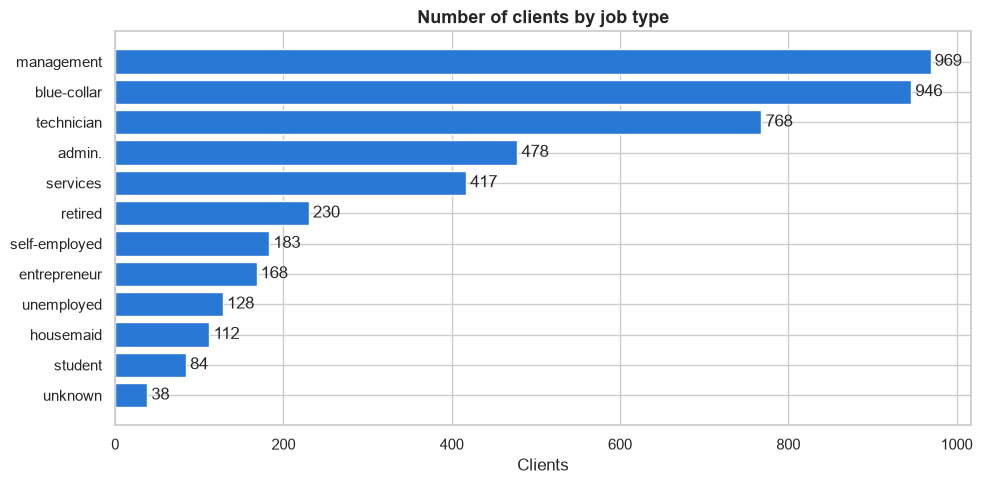

In [31]:
# Chart - 1 visualization code
# bar plot from the pandas DataFrame made in Q7 (Spark did the counting)
data = job_counts_pd.sort_values("count")
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(data["job"], data["count"], color=BLUE)
ax.bar_label(bars, padding=3)
ax.set(title="Number of clients by job type", xlabel="Clients", ylabel=None)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart is the clearest way to compare counts across 12 job types. I made it horizontal so the job names are easy to read, and sorted it so the biggest groups are on top.

##### 2. What is/are the insight(s) found from the chart?

Management (969), blue-collar (946) and technician (768) are the biggest groups and together make up 59.3% of all clients. Students (84) and unknown (38) are the smallest.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Most of the call centre time goes to these three groups, so the call scripts should fit them. The negative side is that the small groups, like students and retired clients, are the ones that subscribe the most (Chart 20 and the job analysis), so planning only by volume would ignore the best converting clients.

#### Chart - 2 - Term deposit subscription (Univariate, target)

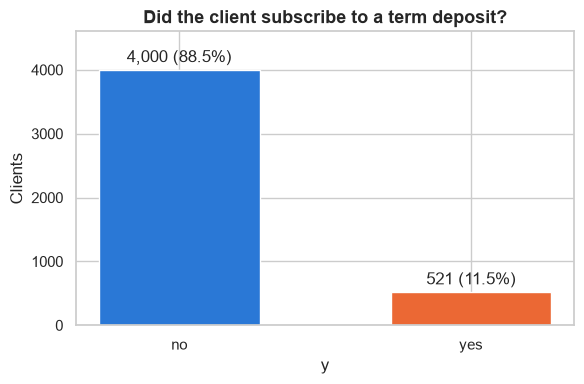

In [32]:
# Chart - 2 visualization code
target = df.groupBy("y").count().orderBy("y").toPandas()
target["pct"] = 100 * target["count"] / target["count"].sum()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(target["y"], target["count"], color=[YES_NO[v] for v in target["y"]], width=0.55)
ax.bar_label(bars, labels=[f"{c:,} ({p:.1f}%)" for c, p in zip(target["count"], target["pct"])], padding=3)
ax.set(title="Did the client subscribe to a term deposit?", xlabel="y", ylabel="Clients", ylim=(0, 4600))
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

The target only has two values, so a simple bar chart with the count and the percentage shows the balance between them better than a pie chart.

##### 2. What is/are the insight(s) found from the chart?

4,000 clients (88.5%) did not subscribe and 521 (11.5%) did. The target is clearly imbalanced: about 1 call in 9 ends in a sale.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It shows how much room there is to improve: every percentage point of extra conversion saves many calls. It is also a warning for the model in Part 3: a model that always says "no" would already be 88.5% accurate, so accuracy alone is not a good metric here.

#### Chart - 3 - Age distribution (Univariate)

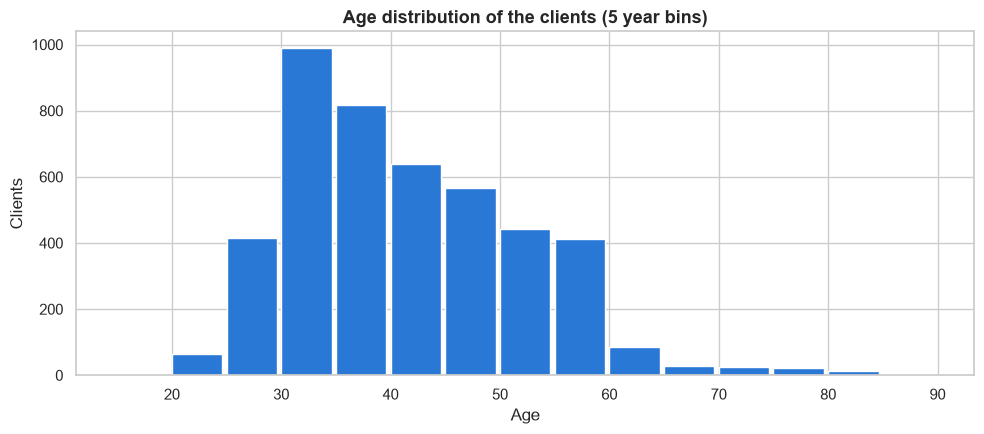

In [33]:
# Chart - 3 visualization code
# 5 year bins counted in Spark, only the bin counts go to pandas
age_bins = (df.withColumn("age_bin", (F.floor(F.col("age") / 5) * 5).cast("int"))
              .groupBy("age_bin").count().orderBy("age_bin").toPandas())

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(age_bins["age_bin"], age_bins["count"], width=4.6, align="edge", color=BLUE)
ax.set(title="Age distribution of the clients (5 year bins)", xlabel="Age", ylabel="Clients")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A histogram shows the shape of a numeric column. I let Spark count the clients in 5 year bins and only sent the bin counts to pandas.

##### 2. What is/are the insight(s) found from the chart?

Most clients are between 30 and 50. The quartiles are 33, 39 and 49 years, and two thirds of the clients (3,011) are in their 30s or 40s. There are very few clients over 60, and the youngest is 19 and the oldest 87.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, the bank mainly talks to working age adults, so the offer and the script should be made for them. On the negative side, the small group over 60 is the one that subscribes the most (Chart 20), and it gets very few calls.

#### Chart - 4 - Balance distribution (Univariate)

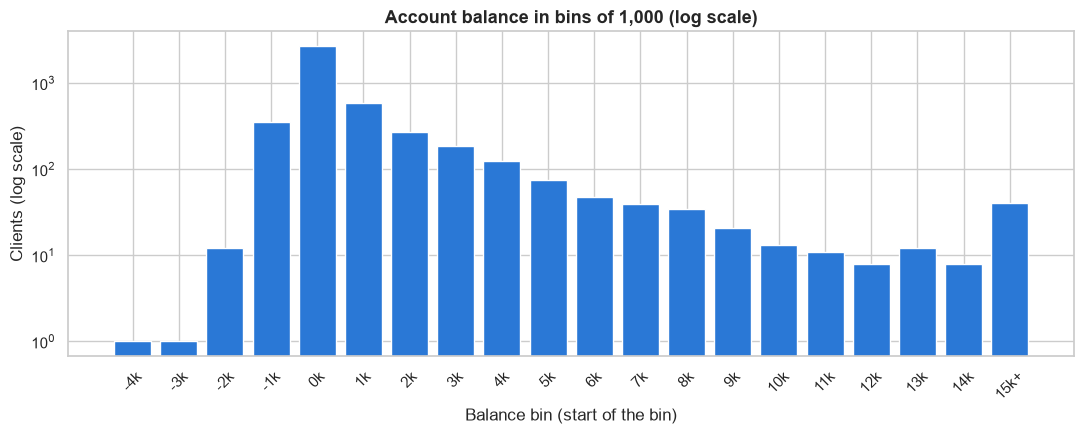

quartiles, 95th and 99th percentile: [69.0, 444.0, 1480.0, 6102.0, 14220.0]


In [34]:
# Chart - 4 visualization code
# balance in bins of 1,000, everything above 15,000 in one last bin
bal_bins = (df.withColumn("bin", F.least(F.greatest(F.floor(F.col("balance") / 1000), F.lit(-4)), F.lit(15)).cast("int"))
              .groupBy("bin").count().orderBy("bin").toPandas())
labels = [f"{b}k" if b < 15 else "15k+" for b in bal_bins["bin"]]

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(labels, bal_bins["count"], color=BLUE)
ax.set_yscale("log")
ax.set(title="Account balance in bins of 1,000 (log scale)", xlabel="Balance bin (start of the bin)", ylabel="Clients (log scale)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print("quartiles, 95th and 99th percentile:", df.approxQuantile("balance", [0.25, 0.5, 0.75, 0.95, 0.99], 0))

##### 1. Why did you pick the specific chart?

The balance is very skewed, so I used bins of 1,000 and a log scale. On a normal scale, everything except the first two bars would be invisible.

##### 2. What is/are the insight(s) found from the chart?

Most clients have a small balance: the median is 444 and 75% have less than 1,480. 366 clients have a negative balance and 357 have exactly 0. The tail is very long: the 95th percentile is 6,102, the 99th 14,220 and the maximum 71,188.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Most clients do not have much money to put into a term deposit, so the clients in the top quarter (above 1,480) are a natural target for this product. The skew is also a warning: average balances (like in Chart 10) are pulled up by a few rich clients, so medians are safer for decisions.

#### Chart - 5 - Contact duration distribution (Univariate)

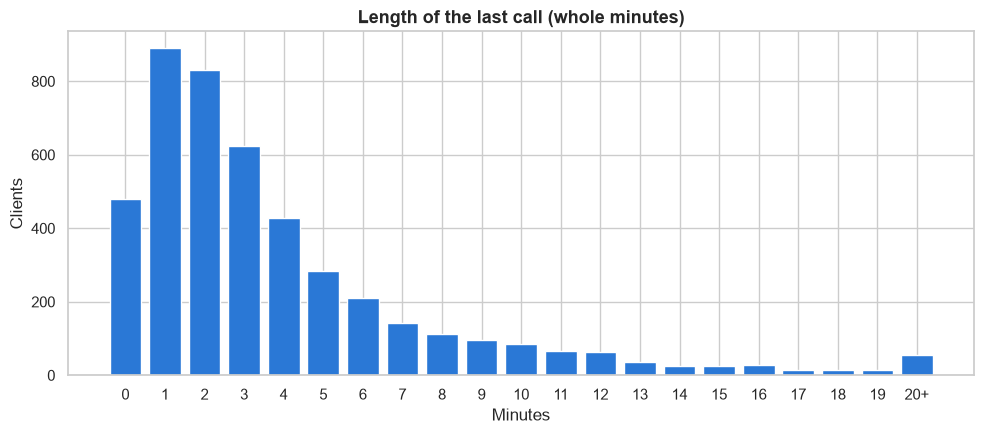

duration quartiles, 95th and 99th percentile (seconds): [104.0, 185.0, 329.0, 763.0, 1259.0]


In [35]:
# Chart - 5 visualization code
# duration in whole minutes, 20 minutes and more in one bin
dur_bins = (df.withColumn("minutes", F.least(F.floor(F.col("duration") / 60), F.lit(20)).cast("int"))
              .groupBy("minutes").count().orderBy("minutes").toPandas())
labels = [str(m) if m < 20 else "20+" for m in dur_bins["minutes"]]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(labels, dur_bins["count"], color=BLUE)
ax.set(title="Length of the last call (whole minutes)", xlabel="Minutes", ylabel="Clients")
plt.tight_layout()
plt.show()
print("duration quartiles, 95th and 99th percentile (seconds):", df.approxQuantile("duration", [0.25, 0.5, 0.75, 0.95, 0.99], 0))

##### 1. Why did you pick the specific chart?

A histogram of the call length in whole minutes shows how long a typical call is and how long the tail is.

##### 2. What is/are the insight(s) found from the chart?

Most calls are short. The median is 185 seconds (about 3 minutes), 75% of the calls are shorter than 329 seconds, and only 5% are longer than 763 seconds. A few calls last more than 20 minutes (the longest is 3,025 seconds).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Partly. Long calls go together with subscriptions (Chart 17), so training staff to keep interested clients talking is useful. But the duration is only known after the call has happened, so it cannot be used to decide whom to call. I will keep this in mind for the model in Part 3.

#### Chart - 6 - Contacts per month (Univariate)

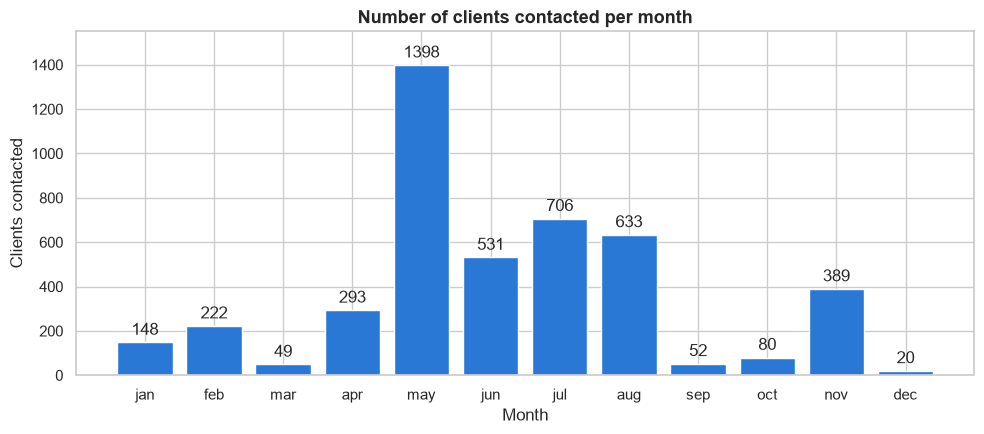

In [36]:
# Chart - 6 visualization code
months_pd = month_stats.orderBy("month_num").toPandas()

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(months_pd["month"], months_pd["contacts"], color=BLUE)
ax.bar_label(bars, padding=3)
ax.set(title="Number of clients contacted per month", xlabel="Month", ylabel="Clients contacted", ylim=(0, 1550))
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Contacts per month is a count over a calendar order, so a bar chart with the months in order works well and the peak is easy to see.

##### 2. What is/are the insight(s) found from the chart?

May is by far the busiest month with 1,398 contacts (30.9% of all calls), followed by July (706), August (633) and June (531). December (20), March (49), September (52) and October (80) have very few calls.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this shows how the campaign effort is planned over the year, which is useful for staffing. Together with Chart 8 it is also a negative finding: the bank calls the most in the month where calls work the worst.

#### Chart - 7 - Marital status and education (Univariate)

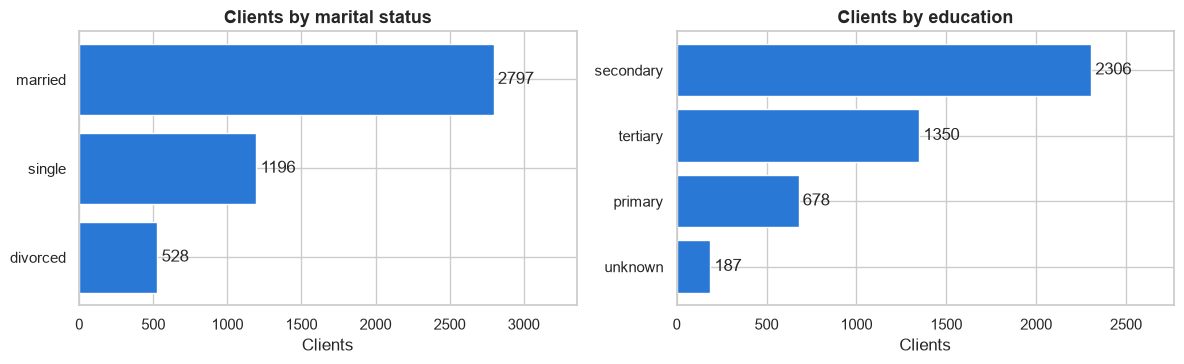

In [37]:
# Chart - 7 visualization code
marital_pd = df.groupBy("marital").count().orderBy("count").toPandas()
education_pd = df.groupBy("education").count().orderBy("count").toPandas()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, data, col, title in [(axes[0], marital_pd, "marital", "Clients by marital status"),
                             (axes[1], education_pd, "education", "Clients by education")]:
    bars = ax.barh(data[col], data["count"], color=BLUE)
    ax.bar_label(bars, padding=3)
    ax.set(title=title, xlabel="Clients", xlim=(0, data["count"].max() * 1.2))
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Two small bar charts side by side show the two main demographic columns in one view.

##### 2. What is/are the insight(s) found from the chart?

Married clients are the biggest group (2,797, 61.9%), then single (1,196) and divorced (528). For education, secondary is the most common (2,306, 51.0%), then tertiary (1,350), primary (678) and unknown (187).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, it describes the typical client the call centre talks to: married with secondary education. On its own it does not show who subscribes, that is in Charts 9 and 11.

#### Chart - 8 - Subscription rate by month (Bivariate: categorical - numerical)

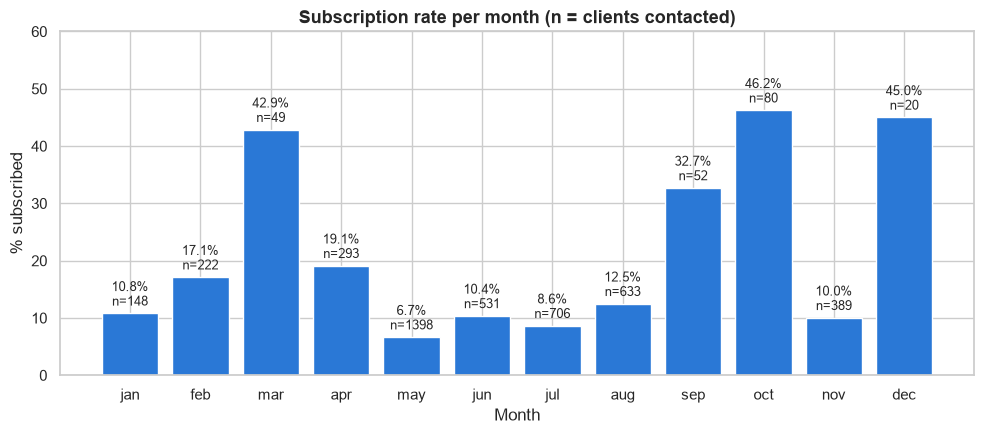

In [38]:
# Chart - 8 visualization code
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(months_pd["month"], months_pd["success_rate_pct"], color=BLUE)
ax.bar_label(bars, labels=[f"{r:.1f}%\nn={n}" for r, n in zip(months_pd["success_rate_pct"], months_pd["contacts"])],
             padding=3, fontsize=9)
ax.set(title="Subscription rate per month (n = clients contacted)", xlabel="Month", ylabel="% subscribed", ylim=(0, 60))
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar per month with the success rate makes it easy to compare the months. I also put the number of contacts on each bar, so a high rate on very few calls is not misread.

##### 2. What is/are the insight(s) found from the chart?

The success rate is lowest in May (6.65%) and July (8.64%), the busiest months. The highest rates are in October (46.25% of 80 calls), December (45.0% of 20), March (42.86% of 49) and September (32.69% of 52).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Shifting part of the calls from May to other months could raise the number of subscriptions without more calls. The negative side is that the months with high rates have very few calls, so part of the effect may come from calling a small, carefully chosen group, which would not work the same way at full volume. The bank should test it before changing the plan.

#### Chart - 9 - Subscription rate by education (Bivariate: categorical - numerical, Part 2 Q5)

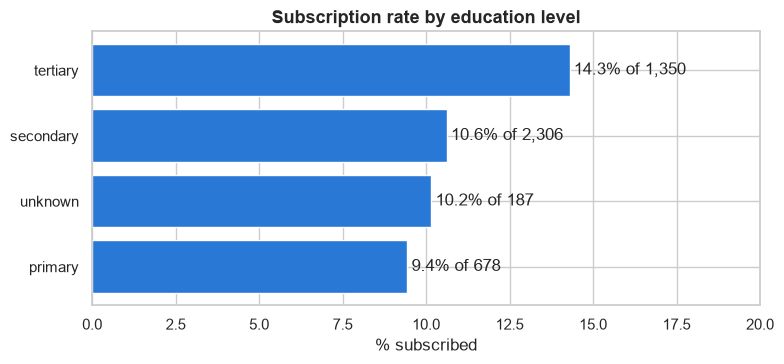

In [39]:
# Chart - 9 visualization code
edu_pd = edu_rate.toPandas().sort_values("subscription_rate_pct")

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.barh(edu_pd["education"], edu_pd["subscription_rate_pct"], color=BLUE)
ax.bar_label(bars, labels=[f"{r:.1f}% of {n:,}" for r, n in zip(edu_pd["subscription_rate_pct"], edu_pd["clients"])], padding=3)
ax.set(title="Subscription rate by education level", xlabel="% subscribed", xlim=(0, 20))
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart compares the subscription rate of the 4 education levels, with the group size on each bar.

##### 2. What is/are the insight(s) found from the chart?

Clients with tertiary education subscribe the most (14.3%, 193 of 1,350), then secondary (10.62%), unknown (10.16%) and primary (9.44%).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, clients with a university degree are a better target, about 1.5 times as likely to subscribe as clients with primary education. The difference is not huge though, so education should be one factor among several and not the main one.

#### Chart - 10 - Average balance by job (Bivariate: categorical - numerical, Part 2 Q3)

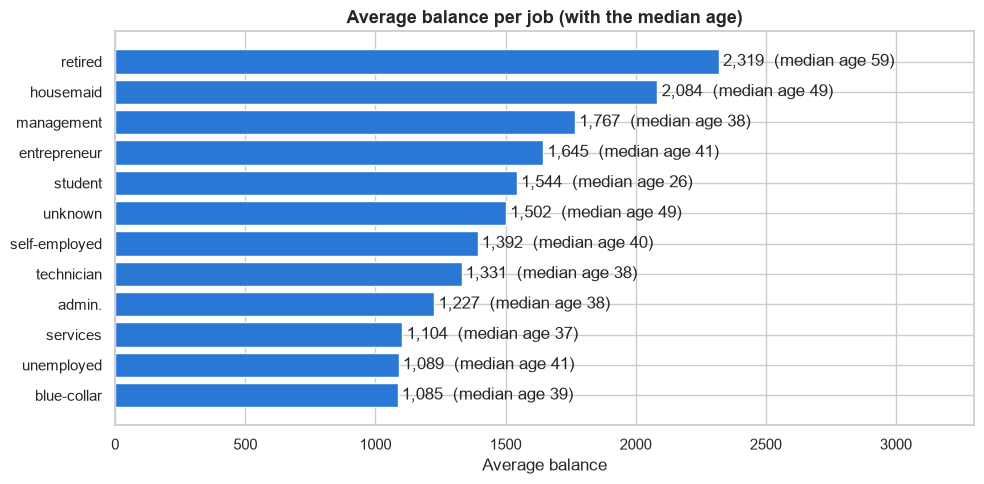

In [40]:
# Chart - 10 visualization code
jobs_pd = job_stats.toPandas().sort_values("avg_balance")

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(jobs_pd["job"], jobs_pd["avg_balance"], color=BLUE)
ax.bar_label(bars, labels=[f"{b:,.0f}  (median age {a})" for b, a in zip(jobs_pd["avg_balance"], jobs_pd["median_age"])], padding=3)
ax.set(title="Average balance per job (with the median age)", xlabel="Average balance", xlim=(0, 3300))
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A sorted bar chart compares the average balance across jobs. I added the median age from the same Spark aggregation to each bar.

##### 2. What is/are the insight(s) found from the chart?

Retired clients have the highest average balance (2,319, median age 59), then housemaids (2,084) and management (1,767). Blue-collar (1,085), unemployed (1,089) and services (1,104) have the lowest.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, retired clients have more money available and (from the job analysis) also subscribe often, so they are a strong target for term deposits. On the negative side, these are averages on a very skewed column (Chart 4), so a few very rich clients can move a job up the list.

#### Chart - 11 - Subscribers per marital status (Bivariate: categorical - categorical, Part 2 Q3)

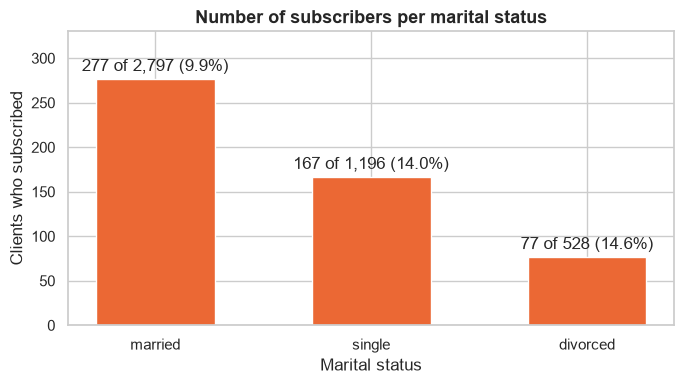

In [41]:
# Chart - 11 visualization code
ms_pd = marital_subs.toPandas()

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(ms_pd["marital"], ms_pd["subscribed"], color=ORANGE, width=0.55)
ax.bar_label(bars, labels=[f"{s} of {c:,} ({r:.1f}%)" for s, c, r in zip(ms_pd["subscribed"], ms_pd["clients"], ms_pd["subscription_rate_pct"])], padding=3)
ax.set(title="Number of subscribers per marital status", xlabel="Marital status", ylabel="Clients who subscribed", ylim=(0, 330))
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart of the number of subscribers per marital status answers Part 2 Q3 directly. I added the group size and the rate on each bar, because the counts alone hide the rate.

##### 2. What is/are the insight(s) found from the chart?

Married clients bring the most subscribers (277), then single (167) and divorced (77). But as a rate, married clients are the lowest (9.9%), while divorced (14.58%) and single (13.96%) clients convert better.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Married clients are the biggest source of subscriptions only because there are so many of them. Single and divorced clients are more likely to say yes, so the bank could give them a bit more priority. Using only the counts would lead to the wrong conclusion here.

#### Chart - 12 - Loan default rate by job (Bivariate: categorical - numerical, Part 2 Q5)

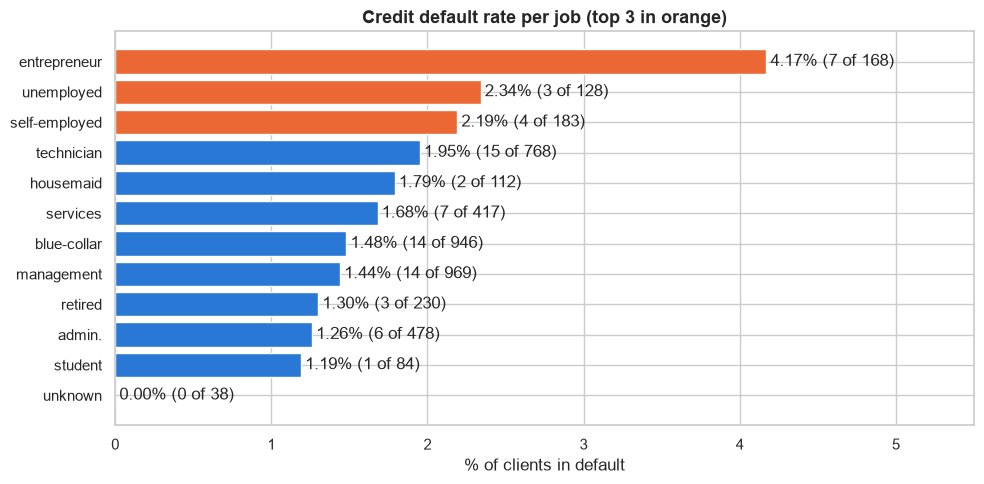

In [42]:
# Chart - 12 visualization code
jd_pd = job_default.toPandas().sort_values("default_rate_pct")
top3 = set(jd_pd.nlargest(3, "default_rate_pct")["job"])

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(jd_pd["job"], jd_pd["default_rate_pct"], color=[ORANGE if j in top3 else BLUE for j in jd_pd["job"]])
ax.bar_label(bars, labels=[f"{r:.2f}% ({d} of {c})" for r, d, c in zip(jd_pd["default_rate_pct"], jd_pd["in_default"], jd_pd["clients"])], padding=3)
ax.set(title="Credit default rate per job (top 3 in orange)", xlabel="% of clients in default", xlim=(0, 5.5))
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A sorted bar chart with the top 3 in a different colour answers the question of which professions default the most, with the number of defaulters shown on each bar.

##### 2. What is/are the insight(s) found from the chart?

Entrepreneurs have the highest default rate (4.17%, 7 of 168), then unemployed (2.34%) and self-employed (2.19%), against 1.68% for all clients. Retired clients and students are among the lowest.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, for risk management: entrepreneurs default more than twice as often as the average client. But the numbers are small (7, 3 and 4 clients in default), so I would not draw strong conclusions per job from this sample.

#### Chart - 13 - Defaulters vs non defaulters (Univariate, Part 2 Q10)

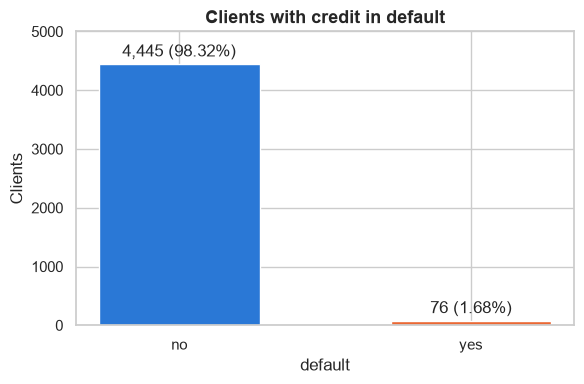

In [43]:
# Chart - 13 visualization code
def_pd = default_stats.toPandas()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(def_pd["default"], def_pd["count"], color=[BLUE, ORANGE], width=0.55)
ax.bar_label(bars, labels=[f"{c:,} ({p:.2f}%)" for c, p in zip(def_pd["count"], def_pd["pct"])], padding=3)
ax.set(title="Clients with credit in default", xlabel="default", ylabel="Clients", ylim=(0, 5000))
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A two bar chart with counts and percentages shows the proportion of defaulters for Part 2 Q10.

##### 2. What is/are the insight(s) found from the chart?

Only 76 clients (1.68%) have credit in default and 4,445 (98.32%) do not.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, default is rare in this client base, which is good news for the bank's credit risk. For modelling, this column carries very little information because almost everyone has the same value.

#### Chart - 14 - Correlation Heatmap

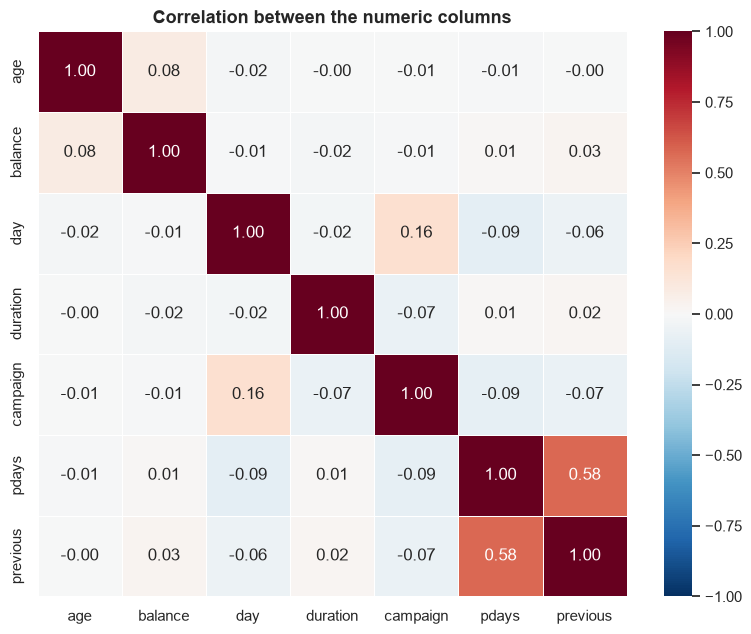

In [44]:
# Correlation Heatmap visualization code
# the correlation matrix is computed by Spark ML (one pass over the data), only the 7x7 result goes to pandas
num_cols = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
vectors = VectorAssembler(inputCols=num_cols, outputCol="features").transform(df).select("features")
corr_matrix = Correlation.corr(vectors, "features").head()[0].toArray()
corr_pd = pd.DataFrame(corr_matrix, index=num_cols, columns=num_cols)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr_pd, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, linewidths=0.5, ax=ax)
ax.set_title("Correlation between the numeric columns")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A heatmap shows all the pairwise correlations between the numeric columns at once. I used a diverging colour scale centred on 0 and computed the matrix with Spark ML's Correlation.

##### 2. What is/are the insight(s) found from the chart?

Almost all correlations are close to 0. The only clear one is between pdays and previous (0.58), which makes sense because both describe earlier campaigns. Day and campaign have 0.16, and age and balance only 0.08. Duration has almost no correlation with the other numeric columns.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Since the numeric columns are not strongly correlated with each other, each one adds its own information and there is no multicollinearity problem for a model, except for pdays and previous, which overlap. It also shows that no single numeric column explains the target linearly, so the categorical columns (poutcome, month, contact) matter a lot.

#### Chart - 15 - Pair Plot

rows in the sample: 2301


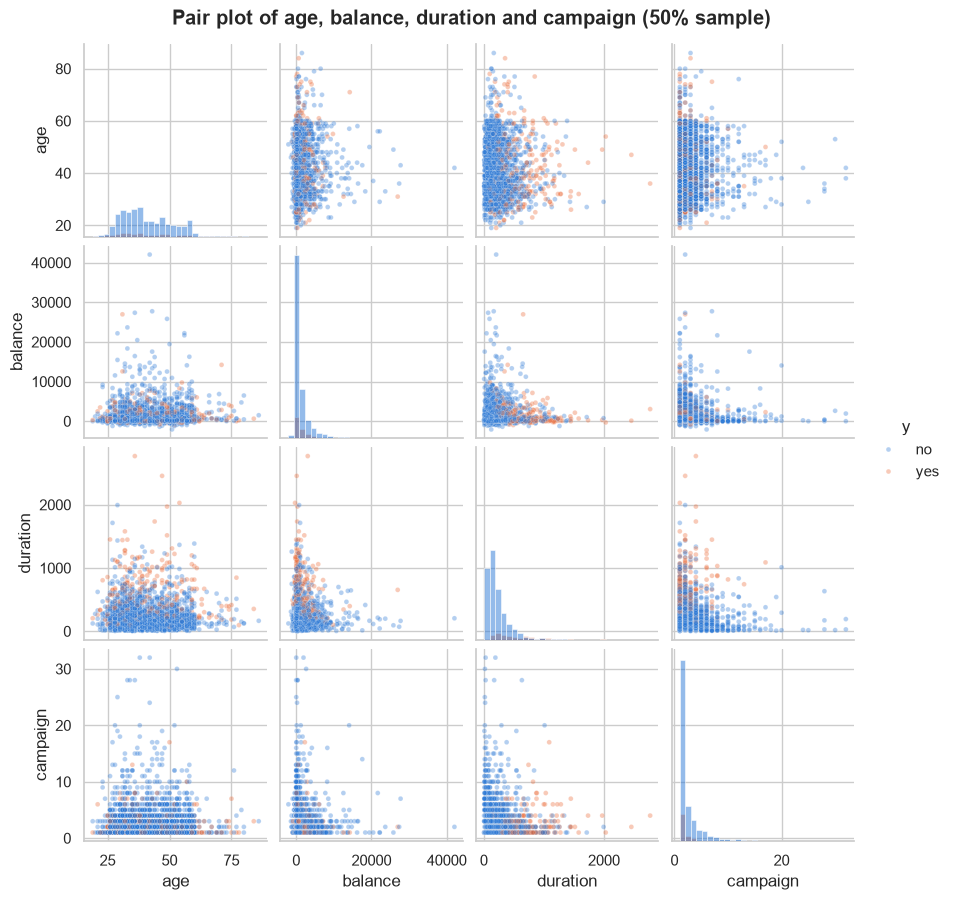

In [45]:
# Pair Plot visualization code
# a 50% sample of 5 columns is enough for a pair plot, Spark does the sampling
pair_pd = df.select("age", "balance", "duration", "campaign", "y").sample(fraction=0.5, seed=42).toPandas()
print("rows in the sample:", len(pair_pd))

g = sns.pairplot(pair_pd, hue="y", hue_order=["no", "yes"], palette=YES_NO,
                 plot_kws={"alpha": 0.35, "s": 12}, diag_kind="hist", diag_kws={"bins": 30}, height=2.2)
g.figure.suptitle("Pair plot of age, balance, duration and campaign (50% sample)", y=1.02, fontweight="bold")
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows the distributions and the scatter plots of several numeric columns at once, coloured by the target. I used a 50% sample from Spark, which is enough to see the patterns.

##### 2. What is/are the insight(s) found from the chart?

The subscribers (orange) stand out on duration: they are spread much higher on the duration axis. On age, balance and campaign the two groups overlap almost completely, although subscribers are a bit more common at low campaign values and at higher ages.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It confirms that call duration separates the two groups much better than age or balance. The negative side is that duration is only known after the call, so for planning the bank has to rely on the weaker signals and on the categorical columns.

#### Chart - 16 - Success rate by contact method (Bivariate, Part 2 Q11)

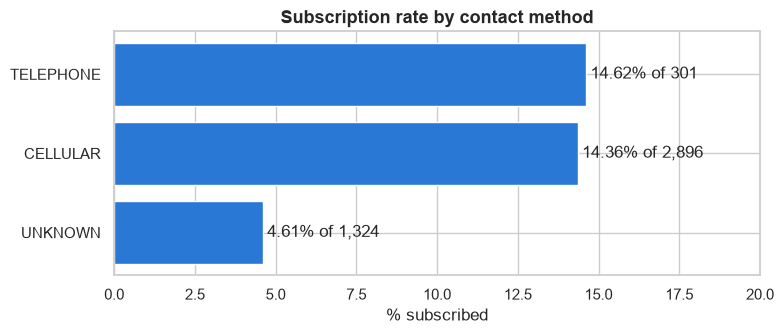

In [46]:
# Chart - 16 visualization code
contact_pd = contact_rate.toPandas().sort_values("success_rate_pct")

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(contact_pd["contact"], contact_pd["success_rate_pct"], color=BLUE)
ax.bar_label(bars, labels=[f"{r:.2f}% of {n:,}" for r, n in zip(contact_pd["success_rate_pct"], contact_pd["clients"])], padding=3)
ax.set(title="Subscription rate by contact method", xlabel="% subscribed", xlim=(0, 20))
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart compares the success rate of the 3 contact types and shows how many clients each one has.

##### 2. What is/are the insight(s) found from the chart?

Telephone has the highest success rate (14.62% of 301 clients), very close to cellular (14.36% of 2,896). Clients with an unknown contact type subscribe only 4.61% of the time (1,324 clients).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The type of phone does not matter much, but missing contact information matters a lot: those clients convert about three times less. Collecting this information properly is a cheap improvement.

#### Chart - 17 - Call duration of subscribers vs non subscribers (Bivariate, Part 2 Q8)

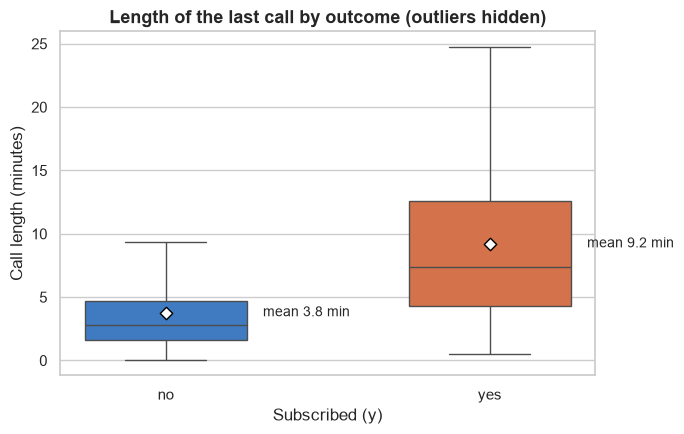

In [47]:
# Chart - 17 visualization code
# two columns to pandas for the box plot, durations shown in minutes
dur_pd = df.select("duration", "y").toPandas()
dur_pd["minutes"] = dur_pd["duration"] / 60

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=dur_pd, x="y", y="minutes", order=["no", "yes"], hue="y", palette=YES_NO, showfliers=False, width=0.5, ax=ax)
means = dur_pd.groupby("y")["minutes"].mean()
for i, label in enumerate(["no", "yes"]):
    # the mean as a white diamond, with its value next to the box
    ax.scatter(i, means[label], marker="D", s=40, color="white", edgecolor="black", zorder=3)
    ax.text(i + 0.3, means[label], f"mean {means[label]:.1f} min", va="center", fontsize=10)
ax.set(title="Length of the last call by outcome (outliers hidden)", xlabel="Subscribed (y)", ylabel="Call length (minutes)")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A box plot compares the whole distribution of the call length between subscribers and non subscribers, not only the average. I hid the outliers so the boxes are readable.

##### 2. What is/are the insight(s) found from the chart?

Calls that ended in a subscription are much longer. The average is 552.7 seconds (9.2 minutes) against 226.3 seconds (3.8 minutes), and the median is 442 against 167 seconds.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Partly. It shows that interested clients talk longer, so staff should not rush calls. But the duration is only known after the call, so it describes the outcome more than it predicts it, and it cannot be used to choose whom to call.

#### Chart - 18 - Age vs balance (Bivariate: numerical - numerical, Part 2 Q9)

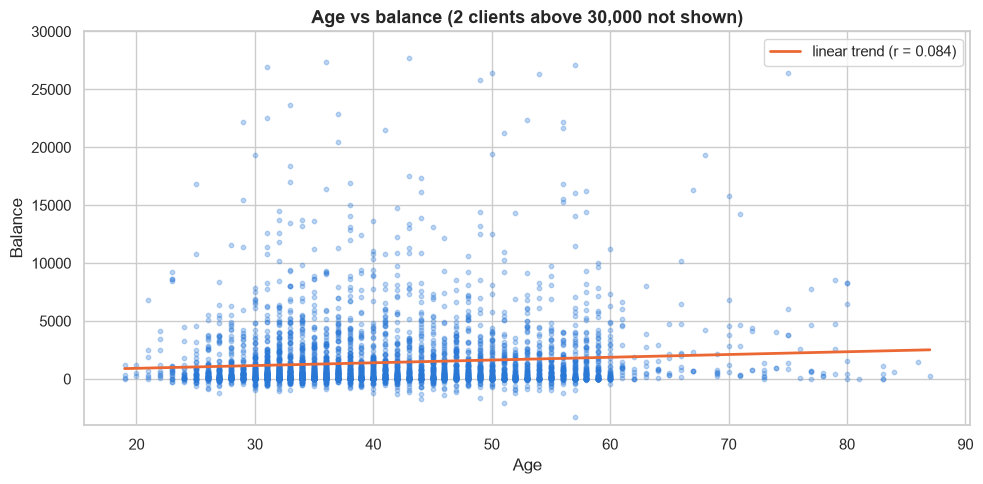

In [48]:
# Chart - 18 visualization code
ab_pd = df.select("age", "balance").toPandas()
cut = 30000
hidden = int((ab_pd["balance"] > cut).sum())
slope, intercept = np.polyfit(ab_pd["age"], ab_pd["balance"], 1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(ab_pd["age"], ab_pd["balance"], s=10, alpha=0.3, color=BLUE)
xs = np.array([ab_pd["age"].min(), ab_pd["age"].max()])
ax.plot(xs, slope * xs + intercept, color=ORANGE, linewidth=2, label=f"linear trend (r = {r_age_balance:.3f})")
ax.set_ylim(-4000, cut)
ax.set(title=f"Age vs balance ({hidden} clients above {cut:,} not shown)", xlabel="Age", ylabel="Balance")
ax.legend()
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot is the standard way to look at two numeric columns. I added a linear trend line and the correlation from Part 2 Q9, and cut the y axis at 30,000 so the main cloud is visible.

##### 2. What is/are the insight(s) found from the chart?

The points form a flat cloud. The trend line rises only slightly with age and the correlation is 0.084, so age explains less than 1% of the differences in balance. Only 2 clients have a balance above 30,000.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, it shows that age alone is a poor way to find clients with a high balance, so the bank should not use age as a proxy for wealth. It also means age and balance can both go into a model without repeating the same information.

#### Chart - 19 - Subscription rate by previous campaign outcome (Bivariate)

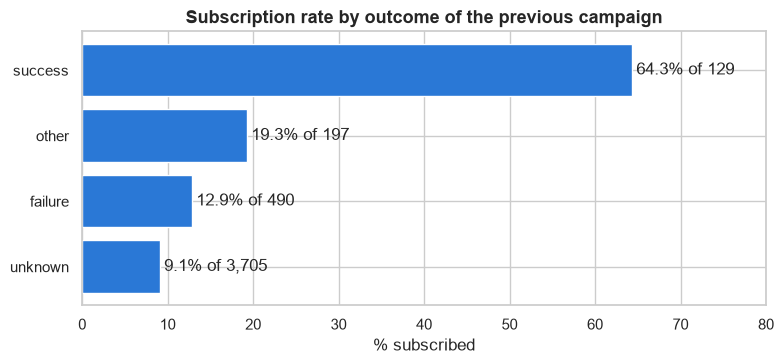

In [49]:
# Chart - 19 visualization code
pout_pd = (df.groupBy("poutcome")
             .agg(F.count("*").alias("clients"), F.round(100 * F.avg(yes), 2).alias("rate"))
             .orderBy("rate").toPandas())

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.barh(pout_pd["poutcome"], pout_pd["rate"], color=BLUE)
ax.bar_label(bars, labels=[f"{r:.1f}% of {n:,}" for r, n in zip(pout_pd["rate"], pout_pd["clients"])], padding=3)
ax.set(title="Subscription rate by outcome of the previous campaign", xlabel="% subscribed", xlim=(0, 80))
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart of the subscription rate per previous outcome, with the group size, shows the effect of the earlier campaign.

##### 2. What is/are the insight(s) found from the chart?

Clients with a successful earlier campaign subscribe 64.3% of the time (129 clients). After "other" it is 19.3%, after a failure 12.9%, and for clients never contacted before (unknown, 3,705 clients) only 9.1%.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this is the strongest single signal in the data. Past successes should be called first in every campaign. The negative side is that this group is small (129 clients), so it cannot carry the campaign on its own.

#### Chart - 20 - Subscription rate by age band (Bivariate)

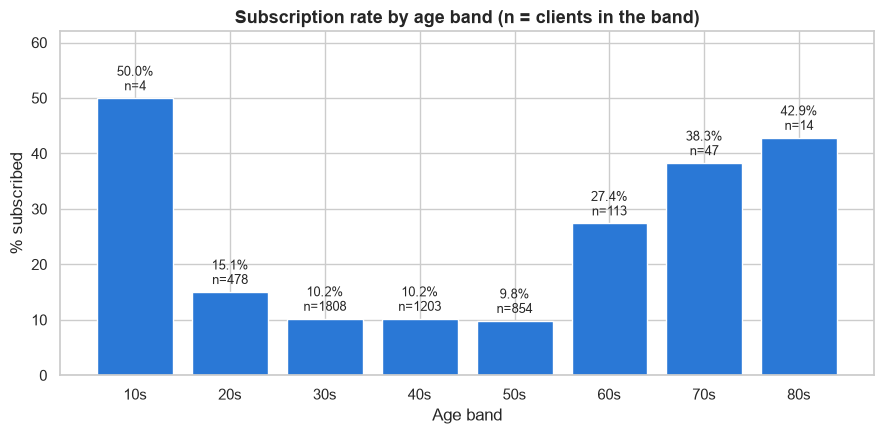

In [50]:
# Chart - 20 visualization code
# 10 year bands, more detail than the 3 groups of the UDF
band_pd = (df.withColumn("band", (F.floor(F.col("age") / 10) * 10).cast("int"))
             .groupBy("band").agg(F.count("*").alias("clients"), F.round(100 * F.avg(yes), 2).alias("rate"))
             .orderBy("band").toPandas())
labels = [f"{b}s" for b in band_pd["band"]]

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(labels, band_pd["rate"], color=BLUE)
ax.bar_label(bars, labels=[f"{r:.1f}%\nn={n}" for r, n in zip(band_pd["rate"], band_pd["clients"])], padding=3, fontsize=9)
ax.set(title="Subscription rate by age band (n = clients in the band)", xlabel="Age band", ylabel="% subscribed", ylim=(0, 62))
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart over 10 year age bands shows the trend in more detail than the 3 groups of the UDF. I show the group size on each bar because some bands are small.

##### 2. What is/are the insight(s) found from the chart?

The rate has a U shape: 15.1% in the 20s, around 10% from 30 to 59, then 27.4% in the 60s, 38.3% in the 70s and 42.9% in the 80s. The teens band has only 4 clients, so its 50% means little.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, older clients are much more likely to subscribe, which fits a savings product like a term deposit. The negative side is that the bank's calls go mostly to the 30 to 59 group, which has the lowest rate.

#### Chart - 21 - Subscription rate by housing and personal loan (Multivariate)

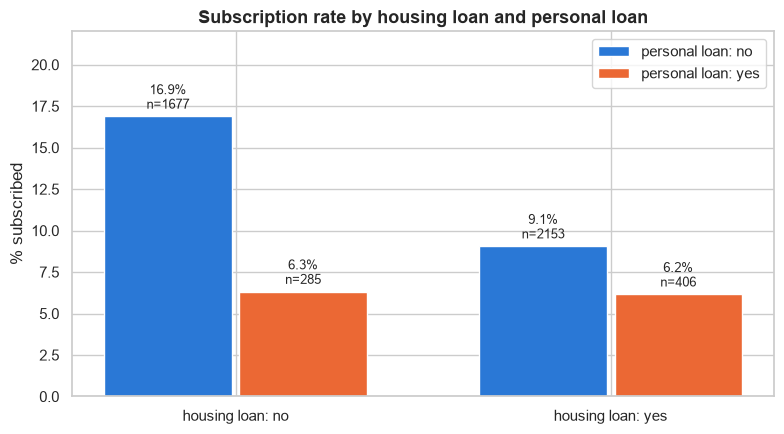

In [51]:
# Chart - 21 visualization code
loans_pd = (df.groupBy("housing", "loan")
              .agg(F.count("*").alias("clients"), F.round(100 * F.avg(yes), 2).alias("rate"))
              .toPandas())
table = loans_pd.pivot(index="housing", columns="loan", values="rate")
counts = loans_pd.pivot(index="housing", columns="loan", values="clients")

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(table.index))
for i, (loan, color) in enumerate([("no", BLUE), ("yes", ORANGE)]):
    bars = ax.bar(x + (i - 0.5) * 0.36, table[loan], width=0.34, color=color, label=f"personal loan: {loan}")
    ax.bar_label(bars, labels=[f"{r:.1f}%\nn={n}" for r, n in zip(table[loan], counts[loan])], padding=3, fontsize=9)
ax.set_xticks(x, [f"housing loan: {h}" for h in table.index])
ax.set(title="Subscription rate by housing loan and personal loan", ylabel="% subscribed", ylim=(0, 22))
ax.legend()
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A grouped bar chart shows the combination of two yes/no columns (housing loan and personal loan) against the subscription rate, which is a multivariate view.

##### 2. What is/are the insight(s) found from the chart?

Clients with no loans subscribe the most (16.9% of 1,677). Any loan lowers the rate: housing loan only 9.1%, personal loan only 6.3%, and both 6.2%.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Clients without loans have more free money for a deposit and should be a priority. The negative side is that more than half of the clients have a housing loan, so the bank cannot avoid them and may need a different offer for them.

#### Chart - 22 - Average balance by age group from Spark SQL (Bivariate, Part 2 Q12)

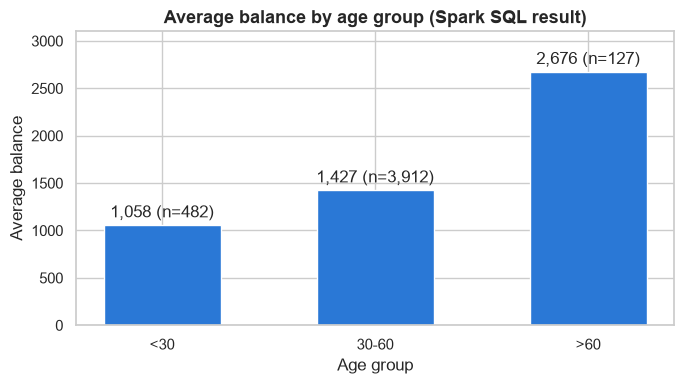

In [52]:
# Chart - 22 visualization code
sql_pd = balance_by_age_sql.toPandas().set_index("age_group").loc[["<30", "30-60", ">60"]]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(sql_pd.index, sql_pd["avg_balance"], color=BLUE, width=0.55)
ax.bar_label(bars, labels=[f"{b:,.0f} (n={n:,})" for b, n in zip(sql_pd["avg_balance"], sql_pd["clients"])], padding=3)
ax.set(title="Average balance by age group (Spark SQL result)", xlabel="Age group", ylabel="Average balance", ylim=(0, 3100))
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart of the Spark SQL result from Part 2 Q12 compares the average balance of the three age groups.

##### 2. What is/are the insight(s) found from the chart?

The average balance rises with age: 1,058 under 30, 1,427 from 30 to 60, and 2,676 over 60.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, the over 60 group has the most money and (Chart 20) the highest subscription rate, so it is a clear target for term deposits. It is only 127 clients though, so it is a niche target and not the whole campaign.

#### Chart - 23 - Subscription rate by quarter (Bivariate, using the quarter column from Q2)

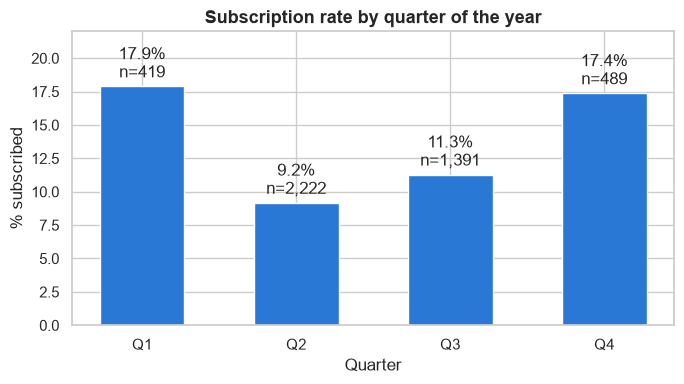

In [53]:
# Chart - 23 visualization code
quarter_pd = (df.groupBy("quarter")
                .agg(F.count("*").alias("clients"), F.round(100 * F.avg(yes), 2).alias("rate"))
                .orderBy("quarter").toPandas())

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(quarter_pd["quarter"], quarter_pd["rate"], color=BLUE, width=0.55)
ax.bar_label(bars, labels=[f"{r:.1f}%\nn={n:,}" for r, n in zip(quarter_pd["rate"], quarter_pd["clients"])], padding=3)
ax.set(title="Subscription rate by quarter of the year", xlabel="Quarter", ylabel="% subscribed", ylim=(0, 22))
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart per quarter uses the quarter column I created in Part 2 Q2 and shows the season effect in four bars.

##### 2. What is/are the insight(s) found from the chart?

Quarter 2 has by far the most clients (2,222) and the lowest rate (9.18%). Quarter 1 (17.9%) and quarter 4 (17.38%) have the highest rates with far fewer calls, and quarter 3 is in between (11.29%).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, it confirms Chart 8 at quarter level: the effort is concentrated in the second quarter, where it pays off the least. Planning more calls in quarters 1 and 4 could raise the number of subscriptions, but it should be tested because those quarters may have had a more selective calling list.

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

What I would suggest to the bank, based on this analysis:

- **Call past successes first.** Clients whose earlier campaign was a success subscribe 64.3% of the time, against 9.1% for first time contacts. They are the cheapest subscriptions the bank can get.
- **Spread the calls over the year.** May had 30.9% of all calls and the worst rate (6.65%). Moving part of those calls to months like March, September, October and December, which convert 33% to 46% of their (fewer) calls, should give more subscriptions for the same work. This needs a test first, because the high rates of the quiet months might partly come from calling a smaller, better chosen group.
- **Give more attention to older clients and students.** Clients over 60 subscribe 37.8% of the time, and students and retired clients have the highest rates by job, while most calls go to clients aged 30 to 60, who convert at 10.2%.
- **Fix the contact data.** Clients with an unknown contact type convert at 4.61%, against about 14.5% when the bank knows the phone type. Collecting this information is cheap and should improve the results.
- **Be careful with clients who have loans.** Clients with neither a housing nor a personal loan convert at 16.9%, clients with both at 6.2%. Product offers for clients with loans might need a different pitch.
- **Use a model to rank clients before calling.** The patterns above are the input for the Spark ML model in Part 3, which predicts the chance of a subscription per client so the call centre can start at the top of the list.

# **Conclusion**

- I explored the bank marketing data (4,521 clients, 17 columns) completely with Apache Spark: loading, schema, summaries, filters, new columns, group bys, a UDF, string functions, correlation and Spark SQL. Only small aggregated results went to pandas for the 23 charts.
- The data has no nulls or duplicates, but "unknown" is used as a missing value, mostly in poutcome (82%) and contact (29%).
- Only 11.5% of the clients subscribed, so any model built on this data has to deal with an imbalanced target.
- The strongest signals for a subscription are a successful previous campaign (64.3%), a longer call (552.7 against 226.3 seconds, but only known after the call), the month of the contact (6.65% in May, over 40% in March, October and December), a known contact type and the client's age (37.8% over 60).
- The balance is very skewed (median 444, maximum 71,188) and has almost no relationship with age (r = 0.084).
- The same Spark code can run on a real cluster without changes, because of lazy evaluation, partitions and distributed aggregations, which is the main reason to use Spark for this kind of analysis on bank sized data.

In [54]:
# stop Spark when the analysis is done
spark.stop()
print("Spark session stopped")

Spark session stopped


### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***